# Supplementary Figure S10. Base-pair score distributions of canonical and non-canonical pairs


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_rubric.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["rubric_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Datasets and tiers


In [2]:
GOOD_C, ALL_C, POOR_C = BLUE, "0.55", ORANGE
PRIORITY_C, SECONDARY_C = ORANGE, BLUE

def good_poor_split(df):
    good = set(_json("reference/reference_sets/reference_set.json")["pdbs"])
    poor = set(_json("reference/reference_sets/reference_set_poor.json")["pdbs"])
    u = df["pdb_id"].str.upper()
    return df[u.isin(good)], df[u.isin(poor)]

def add_tier(df):
    df = df.copy()
    df["issues"] = df["issues"].apply(lambda d: d if isinstance(d, dict) else {})
    df["tier"] = np.where(df["score"] >= 99.995, "Preferred",
                          np.where(df["score"] >= CUT, "Acceptable", "Review"))
    return df

PAIRS_LW = scored_pairs(lw_only=True)
GOOD, POOR = good_poor_split(PAIRS_LW)
print(f"{len(PAIRS_LW):,} scored pairs | curated {len(GOOD):,} | non-curated {len(POOR):,}")


884,207 scored pairs | curated 371,960 | non-curated 512,247


## Score distributions of canonical (Watson-Crick cWW) and non-canonical pairs


text 7.0 pt, axis titles 8.5 pt, panel letters 12.0 pt at 6.73 in (4.46 in saved)


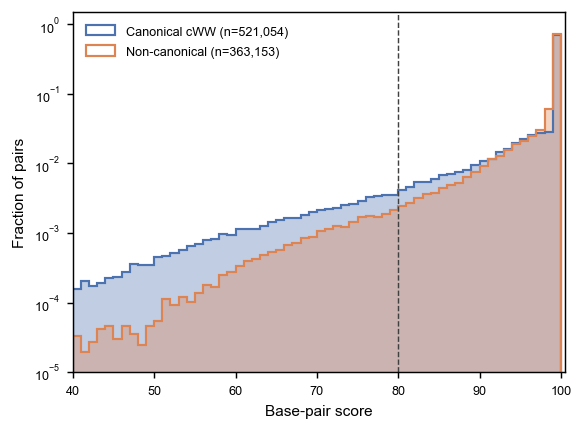

In [3]:
CANON_SEQS = {"GC", "CG", "AU", "UA"}
IS_CANON = (PAIRS_LW["lw_class"] == "cWW") & PAIRS_LW["sequence"].isin(CANON_SEQS)
BINS_D = np.arange(40, 100.5, 1.0)

def draw_d(ax):
    for mask, color, name in ((IS_CANON, BLUE, "Canonical cWW"),
                              (~IS_CANON, ORANGE, "Non-canonical")):
        v = PAIRS_LW.loc[mask, "score"].to_numpy()
        w = np.full(len(v), 1.0 / len(v))
        ax.hist(v, bins=BINS_D, weights=w, histtype="stepfilled", alpha=0.35, color=color)
        ax.hist(v, bins=BINS_D, weights=w, histtype="step", color=color, lw=1.2,
                label=f"{name} (n={len(v):,})")
    ax.axvline(CUT, color="0.25", ls="--", lw=0.8)
    ax.set_yscale("log")
    ax.set_xlim(40, 100.5)
    ax.set_ylim(1e-5, 1.5)
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("Base-pair score")
    ax.set_ylabel("Fraction of pairs")
    ax.legend(loc="upper left")
    finish(ax)


fig, ax = plt.subplots(figsize=(4.6, 3.4))
draw_d(ax)
fig.tight_layout()
def _enforce_print_spec(fig, text_pt=7.0, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    """Ticks and other text at text_pt, axis titles at axis_pt, panel letters at letter_pt, as printed at page_in wide."""
    import matplotlib.text as mtext
    axis = {id(lab) for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label)}
    letters = {id(t) for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)}
    texts = [t for t in fig.findobj(mtext.Text) if t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for t in texts:
            t.set_fontsize((letter_pt if id(t) in letters else axis_pt if id(t) in axis else text_pt) * shrink)
    print(f"text {text_pt} pt, axis titles {axis_pt} pt, panel letters {letter_pt} pt at {page_in} in "
          f"({bb.width + 2 * pad:.2f} in saved)")


_enforce_print_spec(fig)
save(fig, "figures/supplemental/figS10.png")
plt.show()
